<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-072-born-machine.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 072. Modelling probabilities with a quantum circuit

A data set is a list of samples drawn from a probability distribution that nobody has written down. Generative modelling asks for a model distribution from which new samples can be drawn and which is close to the unknown one. A register of qubits measured in the computational basis can serve as such a model, because every measurement returns a random bit string with the probabilities given by the Born rule. A parametrised circuit therefore defines a probability distribution over bit strings, and changing its gate angles changes that distribution. Such a model is called a quantum circuit Born machine.

We are given a data set of a few thousand real numbers $x$. We encode each number as a bit string of $N=6$ bits by cutting the range of $x$ into $2^N=64$ bins. A circuit of rotations and entangling gates prepares a trial state, and we train its angles so that the bit strings measured on the register reproduce the histogram of the data. We compute the exact model probabilities in a state-vector simulation, train with automatic differentiation, and evaluate the trained model from simulated measurement records, as an experiment would.

Sections 2 to 5 set up the simulator, the task and the encoding of numbers as bit strings. Section 6 defines the Born machine and Section 7 the loss function. Sections 8 and 9 compare a circuit without entangling gates with a layered circuit with entanglers, and Section 10 evaluates the trained models from samples. These sections form the core route. Section 11 describes a model from the research literature and can be read at home.

All results are exact state-vector calculations or simulated measurement records with fixed random seeds.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`. JAX does the linear algebra, the automatic differentiation and the random sampling on the CPU, NumPy and SciPy handle the data set and the tables, and Matplotlib draws the figures. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, the CPU is enough
import json, time
from pathlib import Path
import numpy as np
from scipy.special import erf
import jax
import jax.numpy as jnp
from jax import lax
from functools import partial
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, Arc

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
COL = {"target": "black", "data": "#3E8FD0", "model": "#D35A05", "prod": "#5A6270", "samples": "#002B5C", "hi": "#D35A05"}
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
started = time.perf_counter()
NUMBERS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. State-vector simulator

The simulator stores the state of $N$ qubits as a tensor $\psi[b_0,\dots,b_{N-1}]$ with one axis of length 2 per qubit, and qubit 0 is the most significant bit, so the amplitude of the bit string $b_0b_1\dots b_{N-1}$ sits at the flat index
$$k=\sum_{q=0}^{N-1}b_q\,2^{N-1-q}. \tag{1}$$
A rotation generated by a Pauli matrix $\hat P$ is
$$\hat R_P(\theta)=e^{-i\theta\hat P/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\hat P , \tag{2}$$
and a one-qubit gate acts on qubit $q$ by a contraction with axis $q$ of the state tensor. The controlled-$Z$ gate $\widehat{\mathrm{CZ}}$ on the pair $(q,q+1)$ multiplies the amplitude of every bit string with $b_q=b_{q+1}=1$ by $-1$. It is diagonal in the computational basis, so a chain of such gates is one vector of signs $\pm1$ multiplied element-wise into the state. The last check compares the contraction with the Kronecker-product matrix $\hat I\otimes\hat U\otimes\hat I$ on three qubits.

In [2]:
# recap: one-qubit matrices, rotations (2), gates on a state tensor, CZ chain as a sign vector
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)

def rot(P, theta):
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * P

def apply_1q(psi, U, q):
    # psi has shape (2,)*N; contract the gate with axis q and put the new axis back at position q
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)

def bit_table(N):
    # row k holds the bits b_0 ... b_{N-1} of index k, qubit 0 most significant, equation (1)
    k = np.arange(2 ** N)
    return (k[:, None] >> (N - 1 - np.arange(N))) & 1

def cz_chain_signs(N):
    b = bit_table(N)
    return np.prod([1 - 2 * b[:, q] * b[:, q + 1] for q in range(N - 1)], axis=0)

U_test = rot(Y, 0.7) @ rot(Z, -1.1)
psi3 = jax.random.normal(jax.random.PRNGKey(7201), (8,)) + 0j
psi3 = psi3 / jnp.linalg.norm(psi3)
assert jnp.allclose(apply_1q(psi3.reshape(2, 2, 2), U_test, 1).reshape(-1), jnp.kron(jnp.kron(I2, U_test), I2) @ psi3, atol=TOL)
assert jnp.allclose(rot(X, jnp.pi), -1j * X, atol=TOL)
assert list(bit_table(3)[3]) == [0, 1, 1]
CZ01 = jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE))
assert np.allclose(np.diag(np.kron(CZ01, np.eye(2)) @ np.kron(np.eye(2), CZ01)), cz_chain_signs(3))
print("simulator ready: contraction = Kronecker matrix, CZ chain = sign vector", cz_chain_signs(3))

simulator ready: contraction = Kronecker matrix, CZ chain = sign vector [ 1  1  1 -1  1  1 -1  1]


## 3. Generative modelling

We consider an unknown probability distribution $p$ over a space of outcomes and a data set
$$\mathcal D=\{x^{(1)},x^{(2)},\dots,x^{(|\mathcal D|)}\} \tag{3}$$
of $|\mathcal D|$ independent samples drawn from it. The learner sees the samples and never the distribution $p$ itself. A generative model is a family of distributions $q_{\boldsymbol\theta}$, labelled by parameters $\boldsymbol\theta$. New samples can be drawn from $q_{\boldsymbol\theta}$, and $\boldsymbol\theta$ is adjusted so that $q_{\boldsymbol\theta}$ comes close to $p$ in a measure of distance between distributions. Training means choosing $\boldsymbol\theta$ from the data, and a trained model produces new samples that look like the data without copying them.

Classical machine learning offers many such families. A histogram of the data is the simplest one, and it can be sampled by picking a bin with the stored frequency. A Boltzmann machine assigns the probability $e^{-E_{\boldsymbol\theta}(x)}/Z$ through an energy function with trainable couplings. An autoregressive network writes the probability of a vector as a product of conditional probabilities, one component after another. Generative adversarial networks and variational autoencoders transform random noise into samples with a neural network. The quantum model studied here addresses the same task and differs in how the probabilities arise.

The sketch summarises the task, a model trained on samples of an unknown distribution that produces new samples, and the Born machine as one such model.

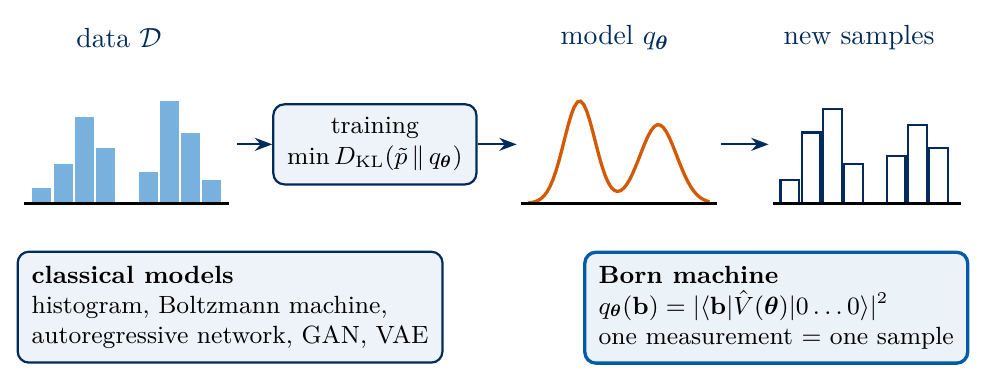

## 4. Data as bit strings

A register of $N$ qubits returns bit strings $\mathbf b=b_0b_1\dots b_{N-1}$, so the data must be written as bit strings before a circuit can model them. Discrete data such as spin configurations or binary images are bit strings already. A continuous variable $x\in[x_{\min},x_{\max}]$ is first discretised. We cut the interval into $2^N$ bins of equal width
$$w=\frac{x_{\max}-x_{\min}}{2^N}, \tag{4}$$
and number them from left to right by the bin index
$$k(x)=\left\lfloor\frac{x-x_{\min}}{w}\right\rfloor\in\{0,1,\dots,2^N-1\}, \tag{5}$$
where $\lfloor\cdot\rfloor$ rounds down to an integer and the right end $x=x_{\max}$ is assigned to the last bin. The index written in binary,
$$k=\sum_{q=0}^{N-1}b_q\,2^{N-1-q}, \tag{6}$$
is the bit string $\mathbf b$, with $b_0$ the most significant bit, which is the ordering (1) of the amplitudes. Every value of $x$ in bin $k$ therefore corresponds to the computational basis state $|\mathbf b\rangle$, and every measured bit string corresponds back to a bin. When a value of $x$ is needed, we take the centre of the bin,
$$x_k=x_{\min}+\Big(k+\frac12\Big)w . \tag{7}$$

For $N=3$ and the interval $[-4,4]$, $w=1$ and there are eight bins labelled $000,001,\dots,111$. The value $x=-0.37$ lies in the bin $[-1,0)$ with index $k=\lfloor 3.63\rfloor=3$, and $3=0\cdot4+1\cdot2+1\cdot1$ is the bit string $011$. The value belongs to the basis state $|011\rangle$, and a measurement that returns $011$ is read as the bin centre $x_3=-0.5$. The discretisation loses the position of $x$ inside its bin, an error of at most $w/2$. Each added qubit doubles the number of bins and halves the width $w$, so the resolution improves exponentially with the number of qubits.

The code implements equations (5) to (7) and runs the example in both directions.

In [3]:
def x_to_index(x, N, xmin, xmax):
    k = np.floor((np.asarray(x) - xmin) / (xmax - xmin) * 2 ** N).astype(int)
    return np.clip(k, 0, 2 ** N - 1)                    # x = xmax goes into the last bin

def index_to_bits(k, N):
    return [(int(k) >> (N - 1 - q)) & 1 for q in range(N)]

def bits_to_index(bits):
    N = len(bits)
    return sum(b * 2 ** (N - 1 - q) for q, b in enumerate(bits))

def bin_centre(k, N, xmin, xmax):
    return xmin + (np.asarray(k) + 0.5) * (xmax - xmin) / 2 ** N

x_example = -0.37
k_example = int(x_to_index(x_example, 3, -4.0, 4.0))
b_example = index_to_bits(k_example, 3)
assert k_example == 3 and b_example == [0, 1, 1] and bits_to_index(b_example) == 3
print(f"x = {x_example} -> bin k = {k_example} -> bit string {''.join(map(str, b_example))}"
      f" -> bin centre x_k = {bin_centre(k_example, 3, -4.0, 4.0):+.2f}")
for N_ in (3, 4, 5, 6, 8, 10):
    print(f"N = {N_:2d}: {2**N_:5d} bins of width {8 / 2**N_:.4f} on [-4, 4]")
for k in range(8):
    assert bits_to_index(index_to_bits(k, 3)) == k

x = -0.37 -> bin k = 3 -> bit string 011 -> bin centre x_k = -0.50
N =  3:     8 bins of width 1.0000 on [-4, 4]
N =  4:    16 bins of width 0.5000 on [-4, 4]
N =  5:    32 bins of width 0.2500 on [-4, 4]
N =  6:    64 bins of width 0.1250 on [-4, 4]
N =  8:   256 bins of width 0.0312 on [-4, 4]
N = 10:  1024 bins of width 0.0078 on [-4, 4]


The sketch draws the encoding for $N=3$, a smooth distribution $p(x)$ with its probabilities in the eight bins labelled by their bit strings, where every value in bin 3 belongs to the basis state $|011\rangle$.

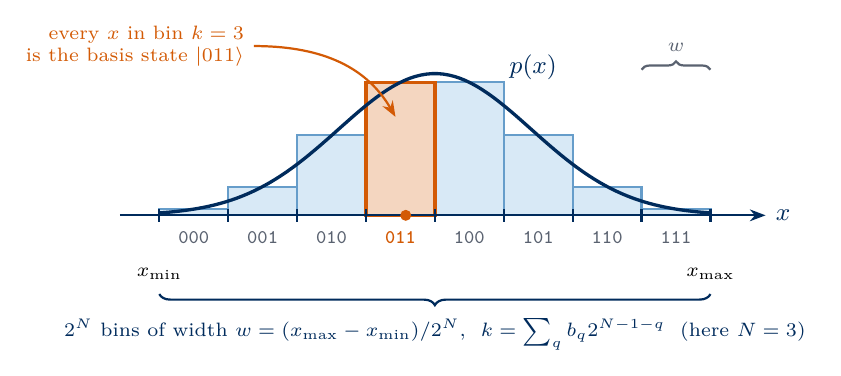

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axs[0]
N3, xa, xb = 3, -4.0, 4.0
edges3 = np.linspace(xa, xb, 2 ** N3 + 1)
gauss = lambda x: np.exp(-x ** 2 / 3)
P3 = np.diff(0.5 * (1 + erf(edges3 / np.sqrt(1.5))))           # bin probabilities of a Gaussian with variance 3/2
for k in range(8):
    hl = (k == 3)
    ax.add_patch(Rectangle((edges3[k], 0), 1, P3[k] / P3.max(), facecolor=COL["hi"] if hl else COL["data"],
                           alpha=0.55 if hl else 0.45, edgecolor=COL["hi"] if hl else "0.4", lw=1.4 if hl else 0.6))
    ax.text(edges3[k] + 0.5, -0.04, format(k, "03b"), ha="center", va="top", fontsize=11,
            color=COL["hi"] if hl else "0.3", fontweight="bold" if hl else "normal")
xx = np.linspace(xa, xb, 300)
ax.plot(xx, gauss(xx), color="black", lw=1.6)
ax.text(1.2, 0.85, r"$p(x)$", color="black")
ax.annotate(r"$x\in$ bin 3 $\leftrightarrow|011\rangle$", xy=(-0.5, 0.8), xytext=(-3.3, 1.2),
            color=COL["hi"], fontsize=11, arrowprops=dict(arrowstyle="->", color=COL["hi"]))
ax.set_xlim(xa - 0.3, xb + 0.6); ax.set_ylim(-0.32, 1.35)
ax.axhline(0, color="0.2", lw=0.8)
ax.text(xa, -0.2, r"$x_{\min}$", ha="center", va="top"); ax.text(xb, -0.2, r"$x_{\max}$", ha="center", va="top")
ax.text(xb + 0.45, 0.0, r"$x$", va="center")
ax.axis("off")
ax.text(0.02, 0.97, "(a)", transform=ax.transAxes, va="top")
ax = axs[1]
ys = [2.0, 1.2, -0.2]
for y, lab in zip(ys, [r"$|0\rangle$", r"$|0\rangle$", r"$|0\rangle$"]):
    ax.text(0.0, y, lab, ha="center", va="center", fontsize=11)
    ax.plot([0.35, 1.2], [y, y], color="0.2"); ax.plot([3.2, 4.0], [y, y], color="0.2")
    ax.add_patch(Rectangle((4.0, y - 0.25), 0.65, 0.5, facecolor="white", edgecolor="0.2"))
    ax.add_patch(Arc((4.325, y - 0.12), 0.45, 0.4, theta1=0, theta2=180, color="0.2"))
    ax.annotate("", xy=(4.5, y + 0.18), xytext=(4.325, y - 0.12), arrowprops=dict(arrowstyle="-", color="0.2"))
    ax.annotate("", xy=(5.4, y), xytext=(4.65, y), arrowprops=dict(arrowstyle="->", color="0.2"))
ax.text(0.0, 0.55, r"$\vdots$", ha="center", fontsize=12); ax.text(4.3, 0.55, r"$\vdots$", ha="center", fontsize=12)
ax.add_patch(FancyBboxPatch((1.2, -0.6), 2.0, 3.0, boxstyle="round,pad=0.05", facecolor="#deebf7", edgecolor="#3182bd", lw=1.3))
ax.text(2.2, 0.9, r"$\hat V(\theta)$", ha="center", va="center", fontsize=13, color="#08519c")
ax.text(5.55, 0.9, "samples\n" + r"$\mathbf{b}\sim q_{\theta}(\mathbf{b})$", va="center", fontsize=10)
ax.set_xlim(-0.4, 7.6); ax.set_ylim(-1.0, 2.7); ax.axis("off")
ax.text(0.0, 0.97, "(b)", transform=ax.transAxes, va="top")
save(fig, "fig_lab072_binning"); plt.close(fig)        # file kept for notes and slides, the sketch above is shown here

## 5. The target distribution and the data set

The target is a mixture of two Gaussian peaks on $x\in[-4,4]$,
$$p(x)\propto\sum_{j=1}^{2}w_j\,\exp\!\Big[-\frac{(x-\mu_j)^2}{2\sigma^2}\Big], \tag{8}$$
with weights $w_1=0.4$ and $w_2=0.6$, centres $\mu_{1,2}=\mp1.6$ and the common width $\sigma=0.6$. On $N=6$ qubits the interval is cut into 64 bins of width $w=0.125$. The exact bin probability $p(\mathbf b)$ is the integral of $p(x)$ over bin $k$, which follows from the error function. We know $p(\mathbf b)$ only because we chose the target. A learner sees the data set, $|\mathcal D|=3000$ values of $x$ drawn from equation (8), each converted to a bit string with equation (5). The data define the empirical distribution
$$\tilde p(\mathbf b)=\frac{n(\mathbf b)}{|\mathcal D|}, \tag{9}$$
where $n(\mathbf b)$ counts how often the bit string $\mathbf b$ occurs in the data set. The tilde marks an estimate obtained from samples. The model is trained on $\tilde p$, and the exact $p$ serves only to judge how well the trained model generalises beyond the finite data set.

The two peaks make the bits strongly correlated. The left peak sits around bin 19, bit string $010011$, and the right peak around bin 44, bit string $101100$, so a value near the left peak has $b_0=0$, $b_1=1$, $b_2=0$, whereas a value near the right peak has the opposite bits.

first five data values: [ 1.12  -1.803 -2.064 -1.169  2.307]
as bit strings        : ['101000', '010001', '001111', '010110', '110010']
bins never seen in the data: 6 of 64
peak bins of p: 19 = 010011, 44 = 101100


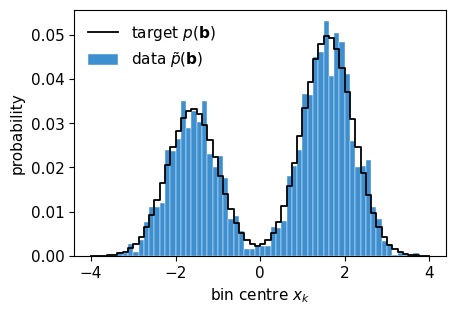

In [5]:
N = 6
K = 2 ** N
XMIN, XMAX = -4.0, 4.0
W_MIX, MU_MIX, SIG_MIX = np.array([0.4, 0.6]), np.array([-1.6, 1.6]), 0.6
edges = np.linspace(XMIN, XMAX, K + 1)
xk = bin_centre(np.arange(K), N, XMIN, XMAX)

def mixture_cdf(x):
    return sum(w * 0.5 * (1 + erf((x - m) / (np.sqrt(2) * SIG_MIX))) for w, m in zip(W_MIX, MU_MIX))

p_exact = np.diff(mixture_cdf(edges)); p_exact /= p_exact.sum()     # exact bin probabilities p(b)

rng = np.random.default_rng(72)                                       # seed of the data set
D_SIZE = 3000
comp = rng.choice(2, size=2 * D_SIZE, p=W_MIX)
x_draw = rng.normal(MU_MIX[comp], SIG_MIX)
x_data = x_draw[(x_draw >= XMIN) & (x_draw <= XMAX)][:D_SIZE]
k_data = x_to_index(x_data, N, XMIN, XMAX)
p_data = np.bincount(k_data, minlength=K) / D_SIZE                     # empirical distribution (9)
BITS = bit_table(N)

assert len(x_data) == D_SIZE and abs(p_data.sum() - 1) < TOL
tv = lambda a, b: 0.5 * float(np.abs(np.asarray(a) - np.asarray(b)).sum())
print("first five data values:", np.round(x_data[:5], 3))
print("as bit strings        :", ["".join(map(str, BITS[k])) for k in k_data[:5]])
print(f"bins never seen in the data: {int((p_data == 0).sum())} of {K}")
print(f"peak bins of p: {int(np.argmax(p_exact[:32]))} = {''.join(map(str, BITS[np.argmax(p_exact[:32])]))},"
      f" {32 + int(np.argmax(p_exact[32:]))} = {''.join(map(str, BITS[32 + np.argmax(p_exact[32:])]))}")
NUMBERS["DataSize"] = str(D_SIZE)
NUMBERS["TVDataTarget"] = f"{tv(p_data, p_exact):.3f}"
NUMBERS["EmptyBins"] = str(int((p_data == 0).sum()))

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar(xk, p_data, width=0.125, color=COL["data"], edgecolor="white", lw=0.3, label=r"data $\tilde p(\mathbf{b})$")
ax.step(np.r_[edges[0], edges[1:]], np.r_[p_exact[0], p_exact], where="pre", color=COL["target"], lw=1.3, label=r"target $p(\mathbf{b})$")
ax.set_xlabel(r"bin centre $x_k$"); ax.set_ylabel("probability"); ax.legend(frameon=False, fontsize=11)
save(fig, "fig_lab072_target"); plt.show()

The bars are the empirical distribution of the 3000 data values, and the line is the exact bin probability. The histogram follows the two peaks with visible fluctuations of a few counts per bin, and some bins in the tails received no data value at all. The total variation distance between the two distributions, defined in Section 7, is 0.065. It sets the scale of the statistical error that the finite data set carries.

## 6. The Born machine

A circuit $\hat V(\boldsymbol\theta)$ with gate angles $\boldsymbol\theta$ acts on the register prepared in $|0\rangle^{\otimes N}$ and produces the state $|\psi(\boldsymbol\theta)\rangle=\hat V(\boldsymbol\theta)|0\rangle^{\otimes N}$. A measurement of every qubit in the computational basis returns the bit string $\mathbf b$ with the Born-rule probability
$$q_{\boldsymbol\theta}(\mathbf b)=\big|\langle\mathbf b|\hat V(\boldsymbol\theta)|0\rangle^{\otimes N}\big|^2 . \tag{10}$$
These probabilities are non-negative and sum to one for every $\boldsymbol\theta$, because the state is normalised, so equation (10) is a family of distributions over the $2^N$ bit strings. A model whose probabilities are squared amplitudes is called a Born machine. The idea was introduced with matrix product states as the source of the amplitudes [1] and compared with Boltzmann machines in Ref. [2]. With a parametrised circuit as the source, the model is the quantum circuit Born machine [3, 4], whose sampling hardness and training were studied in Ref. [5].

The sketch shows the Born machine, a circuit $\hat V(\boldsymbol\theta)$ acting on $|0\rangle^{\otimes N}$ and followed by a measurement of every qubit, which returns one bit string $\mathbf b$ per run.

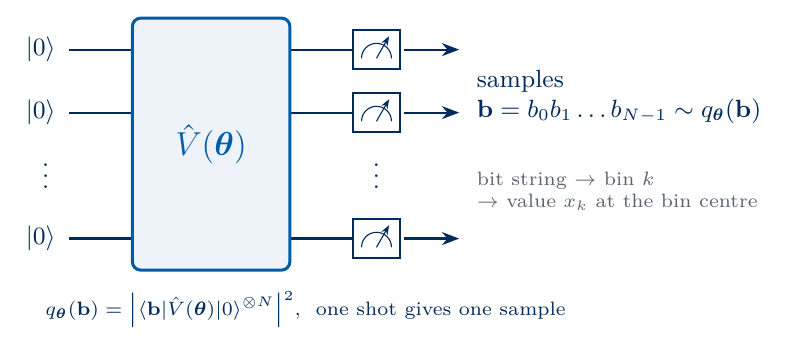

Sampling needs no further computation, since one run of the circuit followed by a measurement of all qubits draws one bit string from $q_{\boldsymbol\theta}$ and, through equation (7), one value of $x$. The probabilities themselves are not directly accessible on a device. An experiment estimates $q_{\boldsymbol\theta}(\mathbf b)$ only as a frequency over many runs, $\tilde q(\mathbf b)=n(\mathbf b)/M$ for $M$ shots, and a bit string of small probability may not appear at all. A simulation, by contrast, stores all $2^N$ amplitudes and gives the exact $q_{\boldsymbol\theta}$.

The circuit is the same object that prepares trial states in the variational quantum eigensolver (VQE). In VQE the measured bit strings serve only to estimate an energy, and the goal is the state that minimises it. In a Born machine the distribution of the bit strings is the goal, and the samples themselves are the output.

In the circuit used throughout, a rotation block applies $\hat R_z(\phi_q)\hat R_y(\vartheta_q)$ to every qubit $q$, and an entangling layer is the chain of $\widehat{\mathrm{CZ}}$ gates on the pairs $(0,1),(1,2),\dots,(N-2,N-1)$. The circuit with $L$ layers is
$$\hat V(\boldsymbol\theta)=\hat B_L\,\widehat{\mathrm{CZ}}_{\rm chain}\cdots\hat B_1\,\widehat{\mathrm{CZ}}_{\rm chain}\,\hat B_0,\qquad \hat B_\ell=\bigotimes_{q=0}^{N-1}\hat R_z(\phi_{\ell q})\,\hat R_y(\vartheta_{\ell q}), \tag{11}$$
with $n=2N(L+1)$ angles. The array `theta` has the shape $(L_{\max}+1,N,2)$, and a mask switches off the layers beyond $L$, so that circuits of every depth $0\le L\le L_{\max}$ share one compiled function. At $L=0$ only the block $\hat B_0$ remains, the product circuit of Section 8. We check that $q_{\boldsymbol\theta}$ sums to one and draw a record of bit strings from a random circuit.

In [6]:
L_MAX = 5
CZ_SIGNS = jnp.asarray(cz_chain_signs(N), dtype=CDTYPE)

def rotation_block(psi, angles):
    # angles[q] = (vartheta_q, phi_q): R_z(phi) R_y(vartheta) on qubit q
    for q in range(N):
        psi = apply_1q(psi, rot(Z, angles[q, 1]) @ rot(Y, angles[q, 0]), q)
    return psi

def born_state(theta, mask):
    # equation (11); mask[l] = 1 keeps layer l + 1, mask[l] = 0 removes its CZ chain and its rotations
    psi = jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)
    psi = rotation_block(psi, theta[0])
    def layer(psi, inputs):
        angles, m = inputs
        psi = (psi.reshape(-1) * jnp.where(m > 0, CZ_SIGNS, 1.0)).reshape((2,) * N)
        return rotation_block(psi, angles * m), None
    psi, _ = lax.scan(layer, psi, (theta[1:], mask))
    return psi.reshape(-1)

@jax.jit
def born_probs(theta, mask):
    return jnp.abs(born_state(theta, mask)) ** 2            # equation (10)

def depth_mask(L):
    return jnp.asarray((np.arange(L_MAX) < L).astype(float))

@partial(jax.jit, static_argnums=2)
def sample_bits(key, q, shots):
    # shots measurements of all qubits: bin indices drawn with probabilities q, by inverting the cumulative sum
    u = jax.random.uniform(key, (shots,)) * jnp.sum(q)
    return jnp.minimum(jnp.searchsorted(jnp.cumsum(q), u), q.shape[0] - 1)

def counts_to_freq(idx, size=K):
    return jnp.bincount(idx, length=size) / idx.shape[0]

theta_rand = jax.random.uniform(jax.random.PRNGKey(7202), (L_MAX + 1, N, 2), minval=0, maxval=2 * np.pi)
q_rand = born_probs(theta_rand, depth_mask(2))
assert abs(float(q_rand.sum()) - 1) < TOL
shots_demo = sample_bits(jax.random.PRNGKey(7203), q_rand, 5)
print("q sums to", float(q_rand.sum()), "| five measured bit strings:",
      ["".join(map(str, BITS[int(i)])) for i in shots_demo], "-> x =", np.round(xk[np.asarray(shots_demo)], 3))
idx_big = sample_bits(jax.random.PRNGKey(7204), q_rand, 200_000)
print(f"total variation between q and the frequencies of 200000 shots: {tv(counts_to_freq(idx_big), q_rand):.4f}")

q sums to 1.0000000000000007 | five measured bit strings: ['101011', '001011', '100100', '100100', '101100'] -> x = [ 1.438 -2.562  0.562  0.562  1.562]
total variation between q and the frequencies of 200000 shots: 0.0078


The frequencies of 200 000 shots agree with the exact probabilities up to the statistical error of the record, which confirms that `sample_bits` draws from $q_{\boldsymbol\theta}$.

## 7. The loss function

Training needs a number that measures how far $q_{\boldsymbol\theta}$ is from the data. The Kullback–Leibler (KL) divergence [6] of $q$ from $p$ is
$$D_{\rm KL}(p\,\|\,q_{\boldsymbol\theta})=\sum_{\mathbf b}p(\mathbf b)\,\ln\frac{p(\mathbf b)}{q_{\boldsymbol\theta}(\mathbf b)} , \tag{12}$$
with the convention $0\ln0=0$, and it is measured in nats because of the natural logarithm. It is non-negative and vanishes only for $q_{\boldsymbol\theta}=p$. It is asymmetric in its arguments and therefore not a distance in the mathematical sense. The weight $p(\mathbf b)$ makes it most sensitive to the bit strings that are frequent in the data.

When $p$ is replaced by the empirical distribution (9), the KL divergence becomes the negative log-likelihood of the data, the standard loss of statistics. Splitting the logarithm gives
$$D_{\rm KL}(\tilde p\,\|\,q_{\boldsymbol\theta})=\sum_{\mathbf b}\tilde p(\mathbf b)\ln\tilde p(\mathbf b)-\sum_{\mathbf b}\tilde p(\mathbf b)\ln q_{\boldsymbol\theta}(\mathbf b) . \tag{13}$$
The first sum is minus the Shannon entropy $H(\tilde p)$ of the data, in nats, which does not depend on $\boldsymbol\theta$. In the second sum each bit string occurs with the weight $n(\mathbf b)/|\mathcal D|$, so the sum over bit strings is a sum over the data points,
$$-\sum_{\mathbf b}\tilde p(\mathbf b)\ln q_{\boldsymbol\theta}(\mathbf b)=-\frac1{|\mathcal D|}\sum_{i=1}^{|\mathcal D|}\ln q_{\boldsymbol\theta}\big(\mathbf b^{(i)}\big)\equiv\mathcal L_{\rm NLL}(\boldsymbol\theta), \tag{14}$$
and therefore
$$D_{\rm KL}(\tilde p\,\|\,q_{\boldsymbol\theta})=\mathcal L_{\rm NLL}(\boldsymbol\theta)-H(\tilde p). \tag{15}$$
Minimising the KL divergence to the data and maximising the likelihood of the data are the same task with the same gradient.

The loss (14) contains $\ln q_{\boldsymbol\theta}(\mathbf b)$ for every bit string in the data. If the model gives a data bit string a vanishing probability, the loss diverges, so the training must start from a model that covers all bit strings. We start from angles close to $\vartheta_q=\pi/2$, for which each qubit is near $|+\rangle$ and $q_{\boldsymbol\theta}$ is close to the uniform distribution $1/64$. On a device the loss is harder to use, because it needs the probability of each data bit string, which can only be estimated from shot frequencies. A zero frequency, common for small probabilities, makes the estimate of $\ln q$ infinite.

We judge a trained model by the KL divergence (12) from the exact target, $D_{\rm KL}(p\,\|\,q_{\boldsymbol\theta})$, which tests generalisation beyond the data, and by the total variation distance
$$d_{\rm TV}(p,q)=\frac12\sum_{\mathbf b}\big|p(\mathbf b)-q(\mathbf b)\big| \tag{16}$$
which is the largest difference between the probabilities that the two distributions assign to any set of bit strings. It lies between 0 and 1 and stays finite when $q$ vanishes on some bit strings.

The gradient of the loss is computed by automatic differentiation of the simulator with `jax.grad`. On a device the gradient comes from the parameter-shift rule. It gives the derivative of each probability $q_{\boldsymbol\theta}(\mathbf b)$ from two circuits whose angle $\theta_j$ is shifted by $\pm\pi/2$, because $q_{\boldsymbol\theta}(\mathbf b)$ is the expectation value of the projector $|\mathbf b\rangle\langle\mathbf b|$. The probabilities of both circuits are estimated from shots. The angles are updated with the Adam optimiser [7], implemented in a few lines, and `lax.scan` runs the whole training loop inside one compiled function.

In [7]:
P_DATA = jnp.asarray(p_data)

def kl_div(p, q):
    # equation (12) in nats; terms with p = 0 contribute zero
    p, q = jnp.asarray(p), jnp.asarray(q)
    return jnp.sum(jnp.where(p > 0, p * (jnp.log(jnp.where(p > 0, p, 1.0)) - jnp.log(q + 1e-300)), 0.0))

def nll(q, k_samples):
    return -jnp.mean(jnp.log(q[k_samples]))               # equation (14)

def kl_loss(theta, mask):
    return kl_div(P_DATA, born_probs(theta, mask))

def adam(loss, theta0, steps, lr):
    # Adam with the standard moment decay rates 0.9 and 0.999; returns the final angles and the loss history
    value_and_grad = jax.value_and_grad(loss)
    def step(carry, i):
        th, m, v = carry
        l, g = value_and_grad(th)
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g ** 2
        th = th - lr * (m / (1 - 0.9 ** (i + 1))) / (jnp.sqrt(v / (1 - 0.999 ** (i + 1))) + 1e-8)
        return (th, m, v), l
    (th, _, _), hist = lax.scan(step, (theta0, jnp.zeros_like(theta0), jnp.zeros_like(theta0)), jnp.arange(steps))
    return th, hist

# equation (15): KL to the data = negative log-likelihood - entropy of the data
q_check = born_probs(theta_rand, depth_mask(2))
S_data = -float(jnp.sum(jnp.where(P_DATA > 0, P_DATA * jnp.log(jnp.where(P_DATA > 0, P_DATA, 1.0)), 0.0)))
assert abs(float(kl_div(P_DATA, q_check)) - (float(nll(q_check, jnp.asarray(k_data))) - S_data)) < 1e-10
print(f"random circuit: KL to the data = {float(kl_div(P_DATA, q_check)):.4f} = NLL {float(nll(q_check, jnp.asarray(k_data))):.4f}"
      f" - entropy of the data {S_data:.4f}")

random circuit: KL to the data = 1.7221 = NLL 5.3552 - entropy of the data 3.6331


The check confirms equation (15) on a random circuit to numerical precision.

## 8. The product circuit

Without entangling gates, $L=0$ in equation (11), the circuit is a product of one-qubit gates and prepares a product state. Each qubit $q$ ends in its own state $\cos(\vartheta_q/2)|0\rangle+e^{i\phi_q}\sin(\vartheta_q/2)|1\rangle$ up to a global phase, and the amplitude of a bit string is a product of one-qubit amplitudes. The Born probability then factorises,
$$q_{\boldsymbol\theta}(\mathbf b)=\prod_{q=0}^{N-1}q_q(b_q),\qquad q_q(0)=\cos^2\frac{\vartheta_q}2,\quad q_q(1)=\sin^2\frac{\vartheta_q}2 , \tag{17}$$
so every bit is an independent biased coin, and the phases $\phi_q$ have no effect on the outcomes. A product circuit cannot represent any correlation between bits.

The sketch contrasts the product circuit, whose bits are independent biased coins, with a circuit whose $\widehat{\mathrm{CZ}}$ gates correlate the bits.

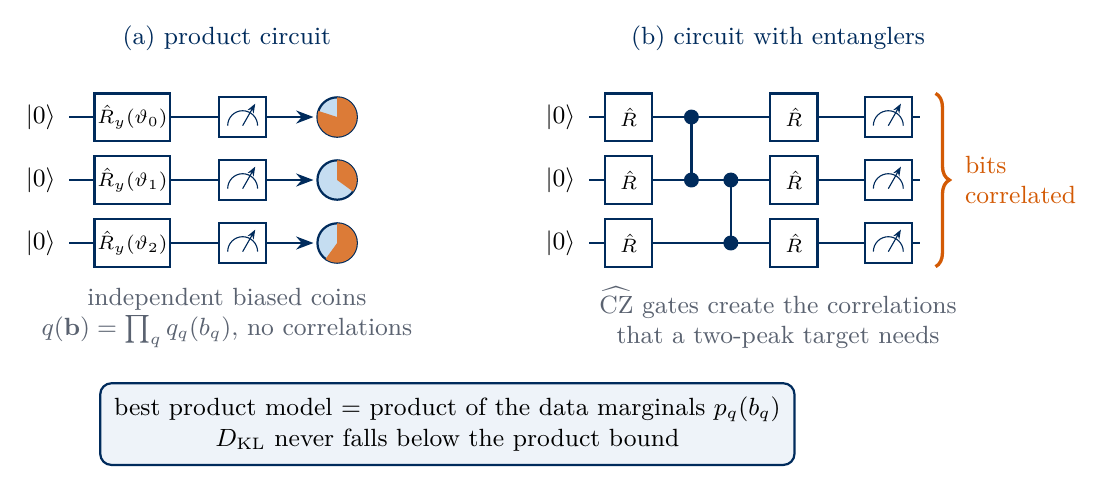

The best product model of a given distribution follows from equation (12). With $q$ of the form (17), the logarithm of $q$ splits into a sum over qubits, and
$$D_{\rm KL}\Big(p\,\Big\|\,\prod_q q_q\Big)=-H(p)-\sum_{q=0}^{N-1}\sum_{b_q\in\{0,1\}}p_q(b_q)\ln q_q(b_q), \tag{18}$$
where $p_q(b_q)$ is the marginal probability that bit $q$ takes the value $b_q$ under $p$. Each inner sum is smallest for $q_q=p_q$, by the non-negativity of the KL divergence between the two one-bit distributions. The best product model is therefore the product of the marginals of the data, and no training of the angles can go below the value of equation (18) at $q_q=p_q$.

For the two-peak target the marginals mix the bits of the two peaks. The product of marginals spreads probability over many bit strings that combine the leading bits of one peak with the trailing bits of the other, which puts probability into bins between and outside the peaks. We first verify the factorisation (17) for random angles and then train the product circuit with the KL divergence to the data.

In [8]:
theta_prod = jax.random.uniform(jax.random.PRNGKey(7205), (L_MAX + 1, N, 2), minval=0, maxval=2 * np.pi)
q_prod = np.asarray(born_probs(theta_prod, depth_mask(0)))
marg = np.array([[np.cos(theta_prod[0, q, 0] / 2) ** 2, np.sin(theta_prod[0, q, 0] / 2) ** 2] for q in range(N)])
q_fact = np.prod(marg[np.arange(N), BITS], axis=1)                   # equation (17)
assert np.allclose(q_prod, q_fact, atol=1e-12)

m1 = (p_data[:, None] * BITS).sum(0)                                  # marginals P(b_q = 1) of the data
q_marg = np.prod(np.where(BITS == 1, m1, 1 - m1), axis=1)             # best product model
kl_bound = float(kl_div(p_data, q_marg))
print("factorisation (19) holds for random angles")
print("data marginals P(b_q = 1):", np.round(m1, 3))
print(f"lower bound of the product circuit, KL(p_data || product of marginals) = {kl_bound:.4f}")
NUMBERS["KLProductBound"] = f"{kl_bound:.3f}"

factorisation (19) holds for random angles
data marginals P(b_q = 1): [0.601 0.457 0.524 0.503 0.496 0.492]
lower bound of the product circuit, KL(p_data || product of marginals) = 0.5002


## 9. Layered circuits with entanglers

Entangling gates between the rotation blocks make the amplitudes, and therefore the bits, correlated. We train circuits (11) of depth $L=0,1,\dots,5$, with $n=12,24,\dots,72$ angles, each from three random starts with $600$ Adam steps and the learning rate $0.05$. The starting angles are $\vartheta=\pi/2$ and $\phi=0$ plus uniform noise of amplitude $0.3$, so every start lies near the uniform distribution. The mask lets one compiled function, vectorised with `jax.vmap`, train all eighteen circuits at once. For each depth we record the KL divergence to the data, which is the training loss, and the KL divergence to the exact target, which tests generalisation.

In [9]:
SEEDS, STEPS, LR = 3, 600, 0.05
depths = np.repeat(np.arange(L_MAX + 1), SEEDS)
masks = jnp.asarray((np.arange(L_MAX)[None, :] < depths[:, None]).astype(float))
theta0 = jax.random.uniform(jax.random.PRNGKey(7206), (len(depths), L_MAX + 1, N, 2), minval=-0.3, maxval=0.3)
theta0 = theta0.at[..., 0].add(np.pi / 2)
t_train = time.perf_counter()
train_all = jax.jit(jax.vmap(lambda th, m: adam(lambda x: kl_loss(x, m), th, STEPS, LR)))
theta_tr, hist_tr = train_all(theta0, masks)
hist_tr = np.asarray(hist_tr)
q_tr = np.asarray(jax.jit(jax.vmap(born_probs))(theta_tr, masks))
print(f"training of {len(depths)} circuits: {time.perf_counter() - t_train:.1f} s")

kl_train = hist_tr[:, -1]
kl_target = np.array([float(kl_div(p_exact, q)) for q in q_tr])
tv_target = np.array([tv(p_exact, q) for q in q_tr])
best = {L: int(np.where(depths == L)[0][np.argmin(kl_train[depths == L])]) for L in range(L_MAX + 1)}
print(" L   n  | KL(data||q) best  | KL(p||q) of best | TV(p,q) of best")
for L in range(L_MAX + 1):
    i = best[L]
    print(f" {L}  {2 * N * (L + 1):3d} |     {kl_train[i]:.4f}        |      {kl_target[i]:.4f}      |     {tv_target[i]:.3f}")
assert abs(kl_train[best[0]] - kl_bound) < 1e-4          # the product circuit reaches the product-of-marginals bound
WORDS = ["Zero", "One", "Two", "Three", "Four", "Five"]
for L in range(L_MAX + 1):
    NUMBERS[f"KLDataL{WORDS[L]}"] = f"{kl_train[best[L]]:.4f}"
    NUMBERS[f"KLTargetL{WORDS[L]}"] = f"{kl_target[best[L]]:.4f}"
    NUMBERS[f"TVTargetL{WORDS[L]}"] = f"{tv_target[best[L]]:.3f}"

training of 18 circuits: 9.3 s
 L   n  | KL(data||q) best  | KL(p||q) of best | TV(p,q) of best
 0   12 |     0.5002        |      0.4823      |     0.414
 1   24 |     0.0847        |      0.0669      |     0.114
 2   36 |     0.0193        |      0.0141      |     0.056
 3   48 |     0.0035        |      0.0137      |     0.055
 4   60 |     0.0029        |      0.0130      |     0.064
 5   72 |     0.0003        |      0.0151      |     0.063


The product circuit converges from all three starts to the bound of equation (18), so its remaining error is the missing correlation between the bits. One entangling layer lowers the KL divergence from 0.5 to below 0.1, and every further layer lowers the training loss again. The figure shows the training curves of the best start at each depth and the final divergences against depth.

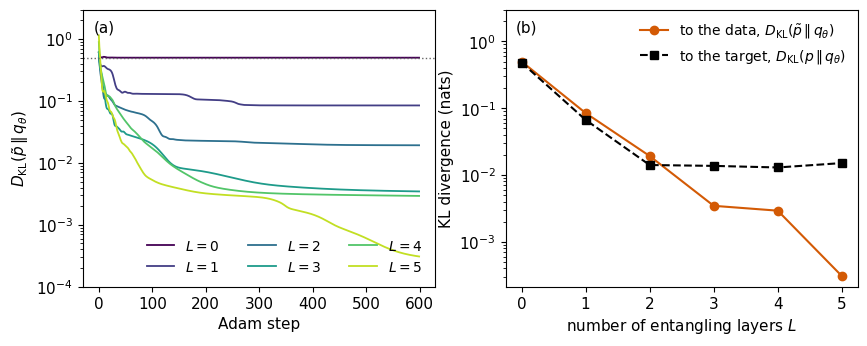

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6))
cmap = plt.get_cmap("viridis")
for L in range(L_MAX + 1):
    axs[0].semilogy(hist_tr[best[L]], color=cmap(L / (L_MAX + 0.5)), lw=1.3, label=f"$L={L}$")
axs[0].set_ylim(1e-4, 3)
axs[0].axhline(kl_bound, color="0.4", ls=":", lw=1.0)
axs[0].set_xlabel("Adam step"); axs[0].set_ylabel(r"$D_{\rm KL}(\tilde p\,\|\,q_{\theta})$")
axs[0].legend(frameon=False, fontsize=10, ncol=3, loc="lower right")
Ls = np.arange(L_MAX + 1)
axs[1].semilogy(Ls, [kl_train[best[L]] for L in Ls], "o-", color=COL["model"], label=r"to the data, $D_{\rm KL}(\tilde p\,\|\,q_{\theta})$")
axs[1].semilogy(Ls, [kl_target[best[L]] for L in Ls], "s--", color=COL["target"], label=r"to the target, $D_{\rm KL}(p\,\|\,q_{\theta})$")
axs[1].set_xlabel(r"number of entangling layers $L$"); axs[1].set_ylabel("KL divergence (nats)")
axs[1].set_ylim(top=3); axs[1].legend(frameon=False, fontsize=10, loc="upper right")
for a, lab in zip(axs, "ab"):
    a.text(0.03, 0.92, f"({lab})", transform=a.transAxes)
save(fig, "fig_lab072_depth"); plt.show()

Panel (a) shows the loss against the Adam step for the best start at each depth, and the dotted line marks the product bound (18), which the $L=0$ curve reaches. Panel (b) shows the final KL divergence against the number of entangling layers, measured against the data (circles) and against the exact target (squares). Both fall quickly up to $L=2$. Beyond it the loss on the data keeps decreasing by an order of magnitude, while the divergence from the target stays near $0.014$. The deeper circuits start to reproduce the statistical fluctuations of the 3000 data values, including empty bins, and these fluctuations are not part of $p$. Fitting these fluctuations is called overfitting, and the divergence from a target that the training never sees detects it. If this picture holds, the saturation level is set by the size of the data set and drops for a larger one. We test this with a second data set of 30 000 values drawn from the same target, and train the circuits with $L=2$, 3 and 5 from the first of their three starts. In practice $p$ is unknown, and a part of the data set held back from training plays the role of the target.

In [11]:
rng_big = np.random.default_rng(7272)                                   # seed of the larger data set
D_BIG = 30_000
comp_b = rng_big.choice(2, size=2 * D_BIG, p=W_MIX)
x_big = rng_big.normal(MU_MIX[comp_b], SIG_MIX)
x_big = x_big[(x_big >= XMIN) & (x_big <= XMAX)][:D_BIG]
p_big = jnp.asarray(np.bincount(x_to_index(x_big, N, XMIN, XMAX), minlength=K) / D_BIG)
sel = np.array([SEEDS * L for L in (2, 3, 5)])                          # first start of each depth
train_big = jax.jit(jax.vmap(lambda th, m: adam(lambda x: kl_div(p_big, born_probs(x, m)), th, STEPS, LR)))
th_big, hist_big = train_big(theta0[sel], masks[sel])
q_big = np.asarray(jax.jit(jax.vmap(born_probs))(th_big, masks[sel]))
print(f"TV(data, p): 3000 values {tv(p_data, p_exact):.3f}, 30000 values {tv(np.asarray(p_big), p_exact):.3f}")
print(" L | KL(p||q), 3000 values | KL(p||q), 30000 values   (same starting angles)")
kl_big = {}
for L, i, q in zip((2, 3, 5), sel, q_big):
    kl_big[L] = float(kl_div(p_exact, q))
    print(f" {L} |        {kl_target[i]:.4f}         |        {kl_big[L]:.4f}")
    NUMBERS[f"KLTargetBigL{WORDS[L]}"] = f"{kl_big[L]:.4f}"
NUMBERS["TVDataBigTarget"] = f"{tv(np.asarray(p_big), p_exact):.3f}"

TV(data, p): 3000 values 0.065, 30000 values 0.015
 L | KL(p||q), 3000 values | KL(p||q), 30000 values   (same starting angles)
 2 |        0.0173         |        0.0117
 3 |        0.0160         |        0.0019
 5 |        0.0147         |        0.0014


With ten times more data the empirical distribution lies closer to the target, at the total variation distance 0.015 instead of 0.065. From the same starting angles, the divergence of the trained circuits from the target then drops from about 0.016 to about 0.002 at $L=3$ and $L=5$. The $L=2$ circuit improves less, because its error comes mostly from the limited circuit. The saturation in panel (b) therefore comes from the finite data set.

The next figure compares the distributions themselves, the product model with the layered models at $L=1$ and $L=3$.

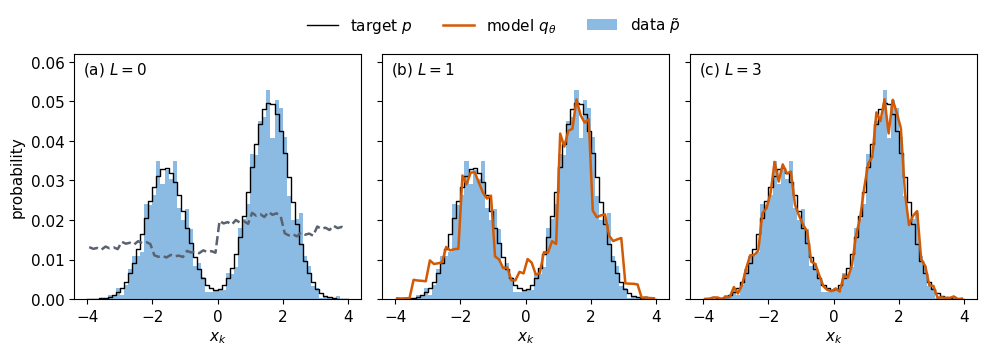

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.6), sharey=True)
for a, L, lab in zip(axs, (0, 1, 3), "abc"):
    a.bar(xk, p_data, width=0.125, color=COL["data"], alpha=0.6, label=r"data $\tilde p$")
    a.step(np.r_[edges[0], edges[1:]], np.r_[p_exact[0], p_exact], where="pre", color=COL["target"], lw=1.0, label=r"target $p$")
    a.plot(xk, q_tr[best[L]], "--" if L == 0 else "-", color=COL["prod"] if L == 0 else COL["model"], lw=1.8, label=r"model $q_{\theta}$")
    a.set_ylim(0, 0.062)
    a.text(0.03, 0.92, f"({lab}) $L={L}$", transform=a.transAxes)
    a.set_xlabel(r"$x_k$")
axs[0].set_ylabel("probability")
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.legend(*axs[1].get_legend_handles_labels(), frameon=False, fontsize=11, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0))
save(fig, "fig_lab072_models"); plt.show()

Panel (a) shows the trained product model (grey dashed line), the product of the marginals described in Section 8. It spreads probability over the whole interval with a weak preference for the right half and misses both peaks. With one entangling layer, panel (b), both peaks appear in the right places with roughly the right weights, while their shapes are still distorted. At $L=3$, panel (c), the model follows the target closely in the peaks and in the tails.

## 10. Evaluation from samples

A trained circuit on a device is used and tested through its samples. We measure the $L=3$ model $M=10^4$ times, convert the bit strings to bin frequencies $\tilde q(\mathbf b)$ and values of $x$, and compare them with the target. The total variation distance (16) can be computed from the frequencies directly. The KL divergence (12) from the target requires $\ln\tilde q(\mathbf b)$ in every bin where $p(\mathbf b)>0$ and is infinite as soon as one such bin received no shot, so a sampled model is judged by the total variation distance.

L = 3: TV(p, q) exact = 0.055, from 10000 shots = 0.051
bins with p > 0 and no shot: 2 -> KL(p || q~) from the shots is infinite
mean and standard deviation of x: data +0.343 1.684 | generated +0.376 1.680 | target +0.320 1.679
fraction of generated x > 0: 0.607  (weight of the right peak 0.6)


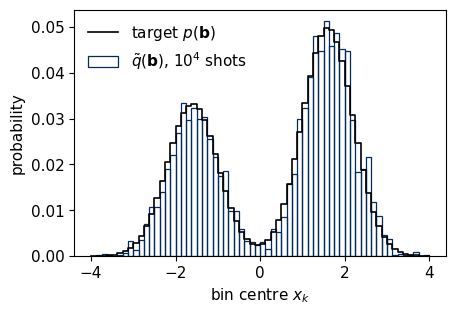

In [13]:
L_EVAL, M_EVAL = 3, 10_000
q_eval = jnp.asarray(q_tr[best[L_EVAL]])
idx_eval = sample_bits(jax.random.PRNGKey(7207), q_eval, M_EVAL)
q_freq = np.asarray(counts_to_freq(idx_eval))
x_gen = np.asarray(xk[np.asarray(idx_eval)])            # generated values of x at the bin centres
tv_exact, tv_sampled = tv(p_exact, q_eval), tv(p_exact, q_freq)
empty = int(np.sum((q_freq == 0) & (p_exact > 0)))
print(f"L = {L_EVAL}: TV(p, q) exact = {tv_exact:.3f}, from {M_EVAL} shots = {tv_sampled:.3f}")
print(f"bins with p > 0 and no shot: {empty} -> KL(p || q~) from the shots is infinite")
print(f"mean and standard deviation of x: data {x_data.mean():+.3f} {x_data.std():.3f} | generated {x_gen.mean():+.3f} {x_gen.std():.3f}"
      f" | target {np.sum(p_exact * xk):+.3f} {np.sqrt(np.sum(p_exact * xk**2) - np.sum(p_exact * xk)**2):.3f}")
print(f"fraction of generated x > 0: {np.mean(x_gen > 0):.3f}  (weight of the right peak 0.6)")
NUMBERS["EvalShots"] = str(M_EVAL)
NUMBERS["TVEvalExact"] = f"{tv_exact:.3f}"
NUMBERS["TVEvalSampled"] = f"{tv_sampled:.3f}"
NUMBERS["EvalEmptyBins"] = str(empty)

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar(xk, q_freq, width=0.125, facecolor="none", edgecolor=COL["samples"], lw=0.9, label=r"$\tilde q(\mathbf{b})$, $10^4$ shots")
ax.step(np.r_[edges[0], edges[1:]], np.r_[p_exact[0], p_exact], where="pre", color=COL["target"], lw=1.2, label=r"target $p(\mathbf{b})$")
ax.set_xlabel(r"bin centre $x_k$"); ax.set_ylabel("probability"); ax.legend(frameon=False, fontsize=11)
save(fig, "fig_lab072_samples"); plt.show()

The bars are the frequencies of the bit strings measured on the trained $L=3$ circuit, and the line is the exact target. The sampled histogram reproduces the two peaks, their relative weight and their widths. Its total variation distance from the target is close to that of the exact model probabilities, so $10^4$ shots suffice to judge the model at this level of accuracy.

The core route ends here.

## 11. An example from the literature

The circuits of Section 9 train every gate angle, including the angles of rotations placed between entangling layers. Deep circuits of this kind become hard to train, because their gradients become very small as the number of qubits grows [8]. One remedy fixes the entangling part of each layer and trains only single-qubit rotations. The quantum scrambling Born machine [9] follows this design. Each of its layers applies trainable rotations of every qubit around a fixed, non-trainable entangling unitary that spreads correlations over the whole register. Ref. [9] considers three choices of this unitary, a Haar-random unitary, a finite-depth brickwork circuit of random two-qubit gates, and evolution for a fixed time under a spin-chain Hamiltonian with nearest-neighbour couplings. Once the fixed unitary creates entanglement close to that of a random state, the trained model reaches a similar accuracy for all three, and only one-qubit angles need to be optimised on a device. A variant treats the couplings and fields of the spin-chain Hamiltonian as trainable parameters as well. Some of the circuits also contain ancilla qubits, which take part in the evolution but are not measured. Ignoring their outcomes sums the Born probabilities over their bits $\mathbf a$, $q(\mathbf b)=\sum_{\mathbf a}|\langle\mathbf b,\mathbf a|\psi\rangle|^2$, so the measured qubits follow a mixture of Born distributions, given by their reduced density matrix. Such mixtures, which require extra qubits, can represent distributions that a pure state of the measured qubits alone cannot.

The sketch shows a register split into measured system qubits and unmeasured ancillas, whose outcomes are summed over to give a mixture of Born distributions.

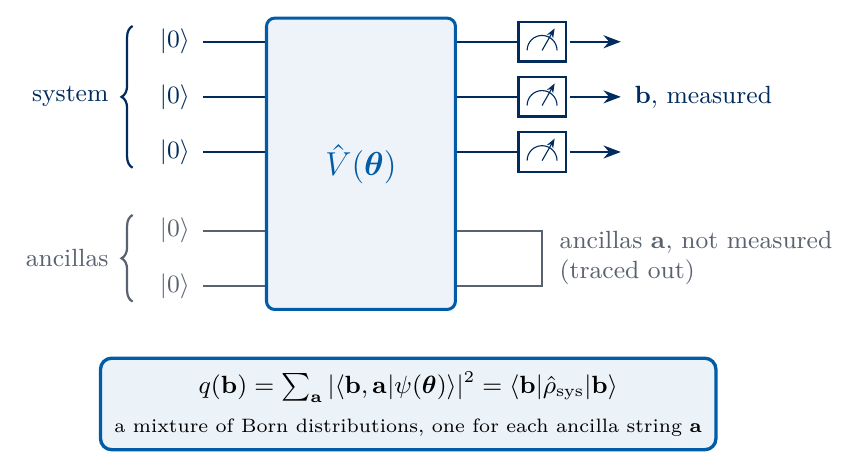

The figure below is a published result of Ref. [9], shown without change and not produced by our simulation. The circuit has ten qubits. Two registers of four qubits encode two continuous variables $x$ and $y$ on a grid of $16\times16$ bins, and the remaining two qubits are ancillas that are traced out. The target is a mixture of four Gaussian peaks. Panel (a) shows the target distribution, panel (b) the distribution learned by the variant with trainable Hamiltonian parameters. Panel (c) shows slices through the peak positions (the dashed lines in panels (a) and (b)), with the target in black and the learned model in red. All four peaks are reproduced with their weights.

![Published result of Ref. [9], not our simulation: target and learned two-dimensional distribution with four peaks](attachment:fig_lab072_qsbm_published.png)

*Published result of Ref. [9], reproduced without change. It is not produced by our simulation.*
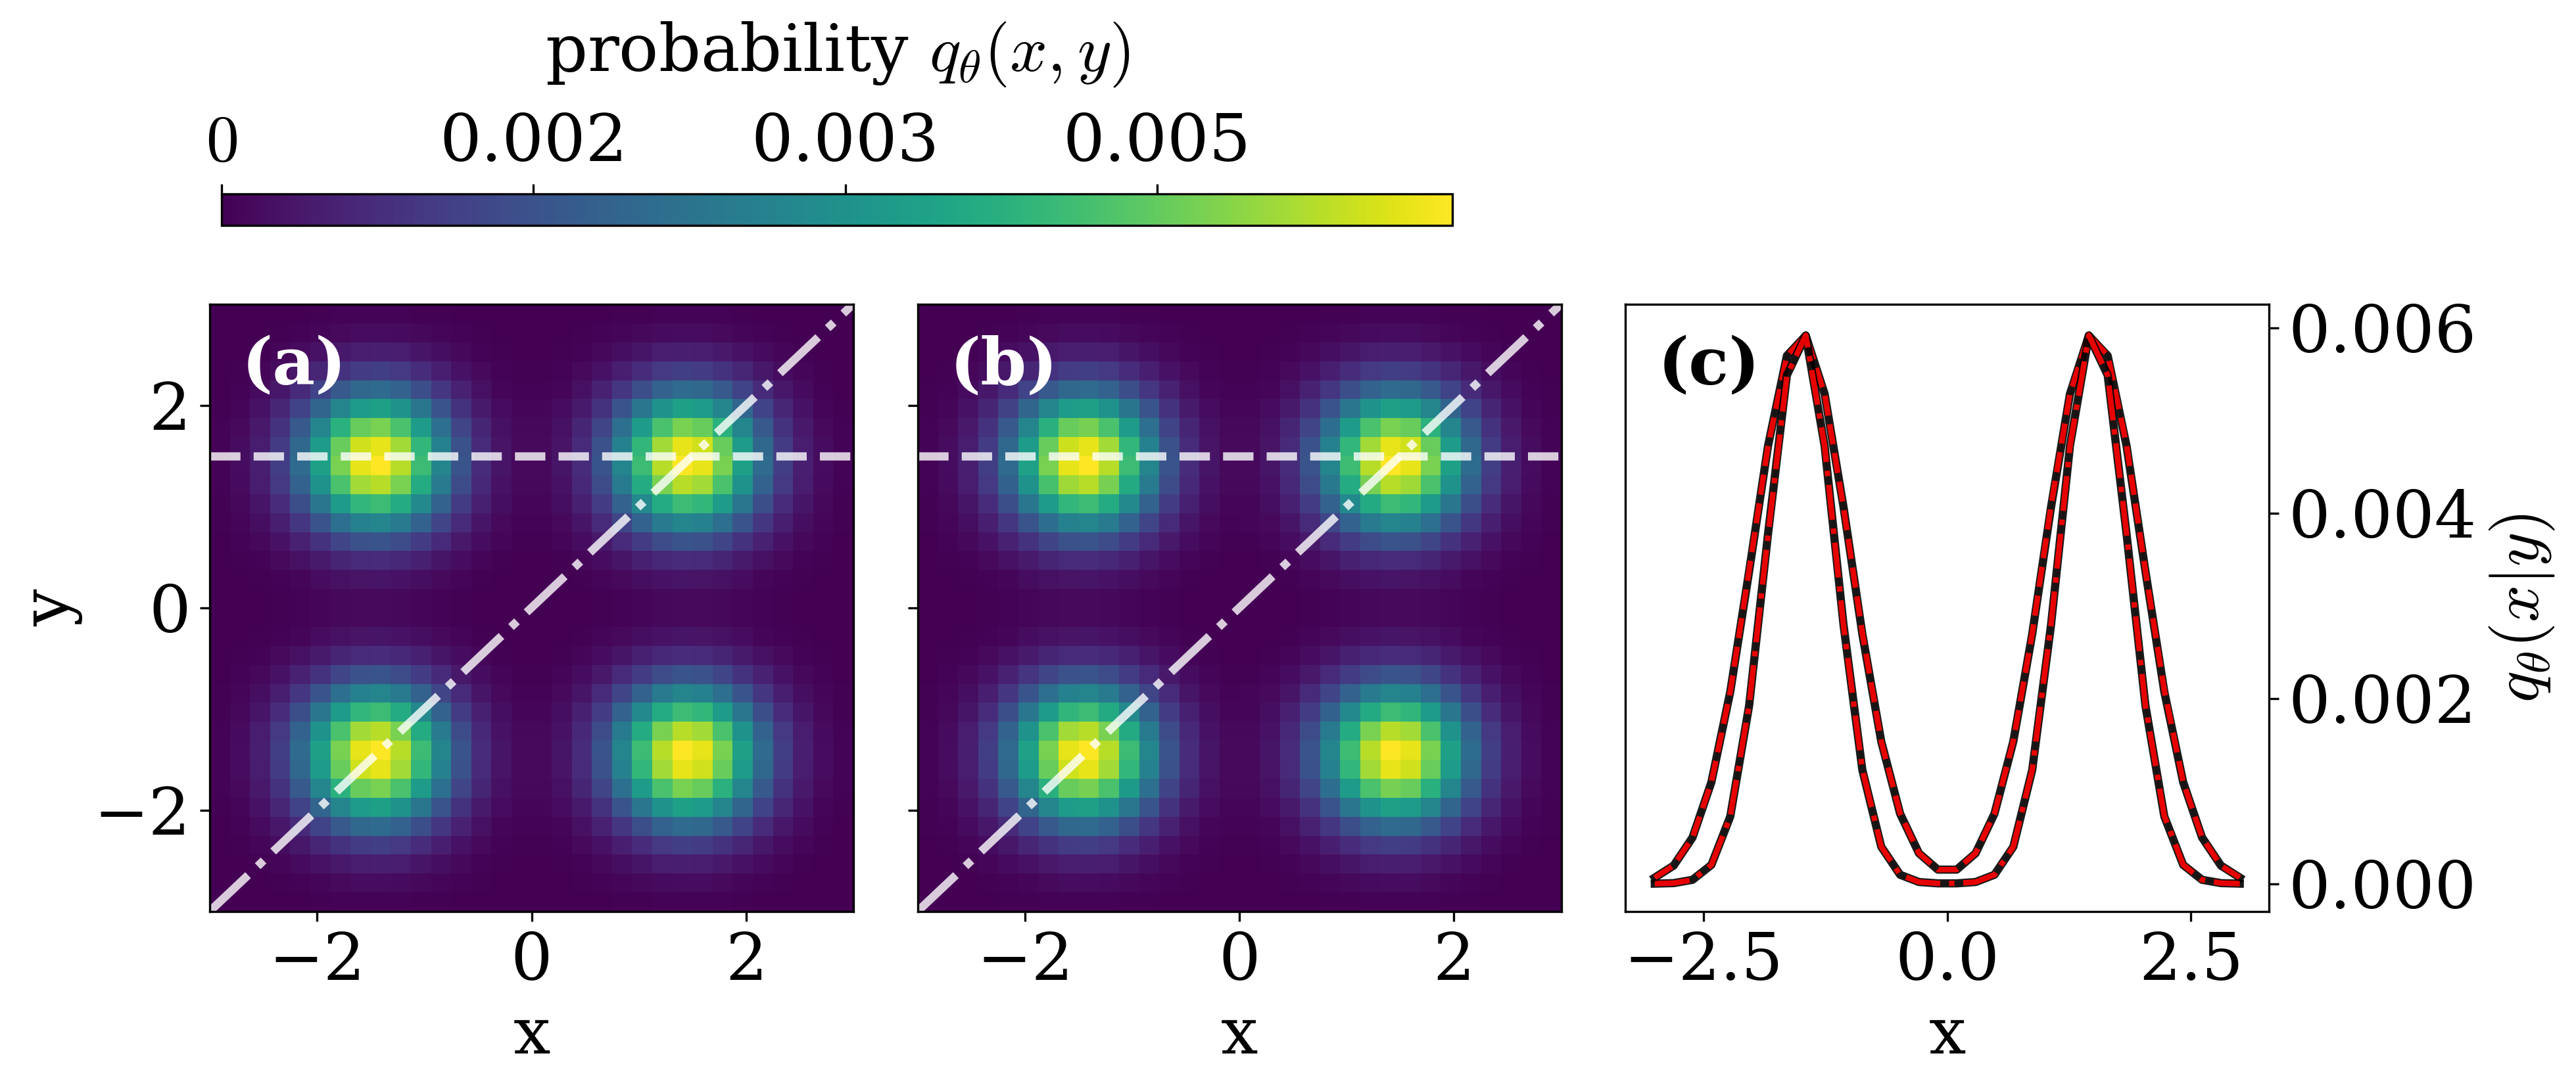

In [14]:
summary = dict(
    experiment="quantum circuit Born machine on N = 6 qubits, exact state vectors, simulated shots",
    target=dict(weights=W_MIX.tolist(), centres=MU_MIX.tolist(), width=SIG_MIX, xmin=XMIN, xmax=XMAX, bins=K),
    data=dict(size=D_SIZE, seed=72, tv_to_target=tv(p_data, p_exact), empty_bins=int((p_data == 0).sum())),
    kl_training=dict(steps=STEPS, learning_rate=LR, starts_per_depth=SEEDS, product_bound=kl_bound,
                     per_depth={int(L): dict(params=2 * N * (L + 1), kl_data=float(kl_train[best[L]]),
                                             kl_target=float(kl_target[best[L]]), tv_target=float(tv_target[best[L]]))
                                for L in range(L_MAX + 1)}),
    evaluation=dict(depth=L_EVAL, shots=M_EVAL, tv_exact=tv_exact, tv_sampled=tv_sampled, empty_bins=empty),
    larger_data_set=dict(size=D_BIG, seed=7272, tv_to_target=tv(np.asarray(p_big), p_exact),
                         kl_target_same_start={int(L): v for L, v in kl_big.items()},
                         kl_target_3000_same_start={int(L): float(kl_target[SEEDS * L]) for L in (2, 3, 5)}),
    runtime_seconds=time.perf_counter() - started)
(RES / "lab072_results.json").write_text(json.dumps(summary, indent=2))
NUMBERS["Runtime"] = f"{summary['runtime_seconds']:.0f}"
with open(FIG / "nb_numbers_lab072.tex", "w") as f:
    for k, v in NUMBERS.items():
        f.write(f"\\newcommand{{\\labseventytwo{k}}}{{{v.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime {summary['runtime_seconds']:.1f} s")

numbers: {'DataSize': '3000', 'TVDataTarget': '0.065', 'EmptyBins': '6', 'KLProductBound': '0.500', 'KLDataLZero': '0.5002', 'KLTargetLZero': '0.4823', 'TVTargetLZero': '0.414', 'KLDataLOne': '0.0847', 'KLTargetLOne': '0.0669', 'TVTargetLOne': '0.114', 'KLDataLTwo': '0.0193', 'KLTargetLTwo': '0.0141', 'TVTargetLTwo': '0.056', 'KLDataLThree': '0.0035', 'KLTargetLThree': '0.0137', 'TVTargetLThree': '0.055', 'KLDataLFour': '0.0029', 'KLTargetLFour': '0.0130', 'TVTargetLFour': '0.064', 'KLDataLFive': '0.0003', 'KLTargetLFive': '0.0151', 'TVTargetLFive': '0.063', 'KLTargetBigLTwo': '0.0117', 'KLTargetBigLThree': '0.0019', 'KLTargetBigLFive': '0.0014', 'TVDataBigTarget': '0.015', 'EvalShots': '10000', 'TVEvalExact': '0.055', 'TVEvalSampled': '0.051', 'EvalEmptyBins': '2', 'Runtime': '36'}
runtime 36.1 s


## 12. Exercises

1. Encode the values $x=3.9$, $x=-4$ and $x=4$ with $N=4$ qubits on $[-4,4]$ and write their bit strings and bin centres.
2. Show that the empirical distribution $\tilde p$ minimises $D_{\rm KL}(\tilde p\,\|\,q)$ over all distributions $q$, and explain why a model that reaches it is not the goal of training.
3. Derive equation (18) and compute the product bound for a distribution with probability $1/2$ on $000\dots0$ and $1/2$ on $111\dots1$.
4. Replace the $\widehat{\mathrm{CZ}}$ chain by $\hat R_{zz}(\pi/2)$ gates on the same pairs and compare the KL divergence at $L=1$ and $L=3$.
5. Repeat the training of Section 9 with $|\mathcal D|=300$ and $|\mathcal D|=30\,000$ data values, and follow how the saturation of $D_{\rm KL}(p\,\|\,q_{\boldsymbol\theta})$ with depth changes.
6. Find the number of shots $M$ for which every bin with $p(\mathbf b)\ge10^{-3}$ receives at least one shot with probability 0.95, and explain what this means for estimating $D_{\rm KL}(p\,\|\,q_{\boldsymbol\theta})$ from samples.
7. Count the circuits needed for one parameter-shift gradient of the $L=3$ circuit, and estimate the shots needed to resolve the probability of a bin with $q_{\boldsymbol\theta}(\mathbf b)\approx10^{-2}$ to a relative error of 10 per cent.

## 13. Summary

A Born machine models a probability distribution over bit strings by the squared amplitudes of a state prepared by a parametrised circuit, and a measurement of all qubits draws one sample from it. Continuous data enter through a discretisation into $2^N$ bins. The bin indices, written in binary with qubit 0 as the most significant bit, are the measured bit strings, and each added qubit halves the bin width. Training minimises the KL divergence to the data, which equals the negative log-likelihood up to the entropy of the data and needs the model probabilities. On a device these probabilities are estimated from shots, and the gradient follows from the parameter-shift rule. A circuit without entangling gates gives independent bits and cannot go below the KL divergence of the product of the marginals, which fails for a two-peak target. Entangling layers create the correlations, and a few layers reproduce the target to within the statistical error of the data set, beyond which deeper circuits fit the fluctuations of the data.

## References

[1] Z.-Y. Han, J. Wang, H. Fan, L. Wang, and P. Zhang, Unsupervised generative modeling using matrix product states, Phys. Rev. X **8**, 031012 (2018), [doi:10.1103/PhysRevX.8.031012](https://doi.org/10.1103/PhysRevX.8.031012).

[2] S. Cheng, J. Chen, and L. Wang, Information perspective to probabilistic modeling: Boltzmann machines versus Born machines, Entropy **20**, 583 (2018), [doi:10.3390/e20080583](https://doi.org/10.3390/e20080583).

[3] J.-G. Liu and L. Wang, Differentiable learning of quantum circuit Born machines, Phys. Rev. A **98**, 062324 (2018), [doi:10.1103/PhysRevA.98.062324](https://doi.org/10.1103/PhysRevA.98.062324).

[4] M. Benedetti, D. Garcia-Pintos, O. Perdomo, V. Leyton-Ortega, Y. Nam, and A. Perdomo-Ortiz, A generative modeling approach for benchmarking and training shallow quantum circuits, npj Quantum Inf. **5**, 45 (2019), [doi:10.1038/s41534-019-0157-8](https://doi.org/10.1038/s41534-019-0157-8).

[5] B. Coyle, D. Mills, V. Danos, and E. Kashefi, The Born supremacy: quantum advantage and training of an Ising Born machine, npj Quantum Inf. **6**, 60 (2020), [doi:10.1038/s41534-020-00288-9](https://doi.org/10.1038/s41534-020-00288-9).

[6] S. Kullback and R. A. Leibler, On information and sufficiency, Ann. Math. Statist. **22**, 79 (1951), [doi:10.1214/aoms/1177729694](https://doi.org/10.1214/aoms/1177729694).

[7] D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).

[8] J. R. McClean, S. Boixo, V. N. Smelyanskiy, R. Babbush, and H. Neven, Barren plateaus in quantum neural network training landscapes, Nat. Commun. **9**, 4812 (2018), [doi:10.1038/s41467-018-07090-4](https://doi.org/10.1038/s41467-018-07090-4).

[9] M. Płodzień, Quantum scrambling Born machine, Phys. Rev. A **114**, 012464 (2026), [doi:10.1103/qccv-flmq](https://doi.org/10.1103/qccv-flmq).